## LIMPIEZA DE DATOS

## Estudiante: Jorge Andrés Ceballos Cruz
### PROGRAMACIÓN III - grupo 4

### Introducción y Objetivo del Análisis

En esta actividad trabajaremos con un conjunto de datos clínicos sobre diabetes recopilados originalmente por el **Instituto Nacional de Diabetes y Enfermedades Digestivas y Renales**. Antes de pasarle cualquier información a un algoritmo de *Machine Learning*, es indispensable hacer un **Análisis Exploratorio de Datos (EDA)** y una buena limpieza para asegurarnos de que la tabla esté bien construida, entender cómo se comportan sus variables y corregir datos faltantes, corruptos o valores atípicos que puedan dañar el funcionamiento de un modelo futuro.

Tomando como referencia la metodología de *Data Wrangling* del libro *Practical Machine Learning with Python* (capítulo 3, pág. 138), organizaremos este cuaderno en cuatro etapas claras:

1. **Diagnóstico inicial :** Revisar el dataset tal como viene descargado para conocer su tamaño, sus tipos de datos, sus estadísticas básicas y detectar valores imposibles o inconsistentes.
2. **Limpieza e Imputación de Datos:** Identificar qué registros tienen datos corruptos o vacíos y aplicar la técnica de imputación más adecuada para rellenarlos sin perder información valiosa.
3. **Verificación después de limpiar:** Volver a revisar la estructura y las estadísticas del dataset ya corregido para comprobar cómo quedó antes de graficar.
4. **Visualización e Interpretación (*Data Visualization*):** Generar gráficos que permitan observar la distribución de los datos, detectar posibles valores atípicos y analizar las relaciones entre variables para extraer conclusiones fáciles de entender.

### Importar las librerias nesesarias 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual para que todas las gráficas salgan limpias y legibles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


* **Pandas (`pd`):** Permite cargar el archivo `.csv` en un *DataFrame*, revisar su estructura, obtener resúmenes estadísticos y aplicar técnicas de imputación para rellenar datos faltantes o corruptos.
* **NumPy (`np`):** Facilita el cálculo numérico y la manipulación de valores nulos reales (`NaN`) al momento de reemplazar datos inconsistentes en el conjunto de datos.
* **Matplotlib (`plt`):** Es la herramienta base para graficar en Python; nos permite controlar el tamaño, los títulos, los ejes y el formato general de cada figura.
* **Seaborn (`sns`):** Trabaja sobre Matplotlib para construir gráficos estadísticos más claros y visuales (como histogramas, diagramas de caja para detectar valores atípicos y mapas de calor de correlación).

## Carga de Datos y diagnostico inicial

In [2]:
# Crear el DataFrame cargando el archivo CSV
df = pd.read_csv('diabetes.csv')

In [3]:
# Revisar la geometría del dataset (filas, columnas)
print(f"Dimensiones del DataFrame: {df.shape[0]} filas y {df.shape[1]} columnas")

Dimensiones del DataFrame: 768 filas y 9 columnas


Primeras 5 filas del dataset

In [5]:
display(df.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Nombres de las columnas

In [8]:
print("Nombres de las columnas:",df.columns.values.tolist())

Nombres de las columnas: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


Inspección de valores faltantes

In [9]:
print("Columns with Missing Values::", df.columns[df.isnull().any()].tolist())
print("Number of rows with Missing Values::", len(df.isnull().any(axis=1).to_numpy().nonzero()[0].tolist()))
print("Sample Indices with missing data::", df.isnull().any(axis=1).to_numpy().nonzero()[0].tolist()[0:5])

Columns with Missing Values:: []
Number of rows with Missing Values:: 0
Sample Indices with missing data:: []


NOTA: En teoria el datasate no tiene valores faltantes (Nulos)

Tipos de datos y estructura general

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [10]:
print("Summary Stats:")
display(df.describe())

Summary Stats:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### Detección de Datos Corruptos Disfrazados de Ceros (`0`)

Al revisar los resultados anteriores, nos encontramos con un detalle clave: en teoría, Pandas nos indica que **no existen valores nulos (`NaN`)** en toda la base de datos. Sin embargo, al observar la fila de valores mínimos (`min`) en el resumen estadístico (`describe()`), vemos que varias variables clínicas registran un **`0`**.

La explicación de esto es que, al recopilar o digitalizar los datos, las mediciones que no se tomaron **no se dejaron como espacios en blanco, sino que se rellenaron con ceros**. Mientras que en columnas como `Pregnancies` (cero embarazos) o `Outcome` (0 = diagnóstico negativo de diabetes) el cero es un dato totalmente normal y válido, en mediciones médicas como `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` y `BMI` tener cero es biológicamente imposible en una persona viva.

Por lo tanto, esos ceros son en realidad **datos faltantes o corruptos** camuflados. A continuación, vamos a contar cuántos ceros hay exactamente en cada columna para saber qué tan grande es el problema y elegir la mejor técnica para corregirlos.

In [11]:
# Conteo de valores iguales a cero (0) por columna para identificar datos corruptos
print("Valores iguales a 0 por columna:")
print((df == 0).sum())

Valores iguales a 0 por columna:
Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


### Descripción de las Variables del Dataset

El conjunto de datos cuenta con **9 columnas** (8 variables con información clínica y 1 variable con el diagnóstico final). Entender qué representa cada una por su nombre nos permite identificar dónde el valor `0` es normal y dónde corresponde a un dato corrupto o no registrado:

* **`Pregnancies` (Embarazos):** Cantidad de embarazos que ha tenido la paciente. Aquí **el `0` es totalmente válido**, ya que simplemente indica que no ha tenido hijos.
* **`Glucose` (Glucosa):** Nivel de azúcar en la sangre. Un valor de **`0` es imposible** en una persona viva, por lo que corresponde a un dato corrupto.
* **`BloodPressure` (Presión arterial):** Medida de la presión sanguínea. Tener **`0` de presión arterial es imposible**, así que son mediciones faltantes.
* **`SkinThickness` (Grosor de la piel):** Medida del grosor de la piel. Ninguna persona tiene **`0` de grosor de piel**, lo que confirma que son datos no registrados.
* **`Insulin` (Insulina):** Nivel de insulina de la paciente. Presenta una gran cantidad de ceros y, como tener **`0` de insulina es biológicamente imposible**, sabemos que son datos corruptos.
* **`BMI` (Índice de Masa Corporal):** Relación entre el peso y la estatura. Un valor de **`0` es físicamente imposible**, por lo que también representa datos faltantes.
* **`DiabetesPedigreeFunction` (Antecedentes hereditarios):** Es un puntaje numérico que resume qué tanta predisposición genética o familiar tiene la paciente a desarrollar diabetes.
* **`Age` (Edad):** Edad de la paciente en años.
* **`Outcome` (Resultado / Diagnóstico):** Es la variable objetivo que indica si la paciente tiene diabetes (`1`) o no (`0`). Aquí **el `0` es válido**, ya que representa un diagnóstico negativo.

### Exploración Visual Inicial (Datos Crudos)

Antes de corregir los datos corruptos, realizamos una primera ronda de visualizaciones sobre el dataset original para observar cómo se comportan las variables, detectar visualmente los valores atípicos (*outliers*) y evidenciar cómo los ceros imposibles distorsionan las distribuciones. Más adelante repetiremos estas mismas gráficas sobre el dataset limpio para comparar el antes y el después.

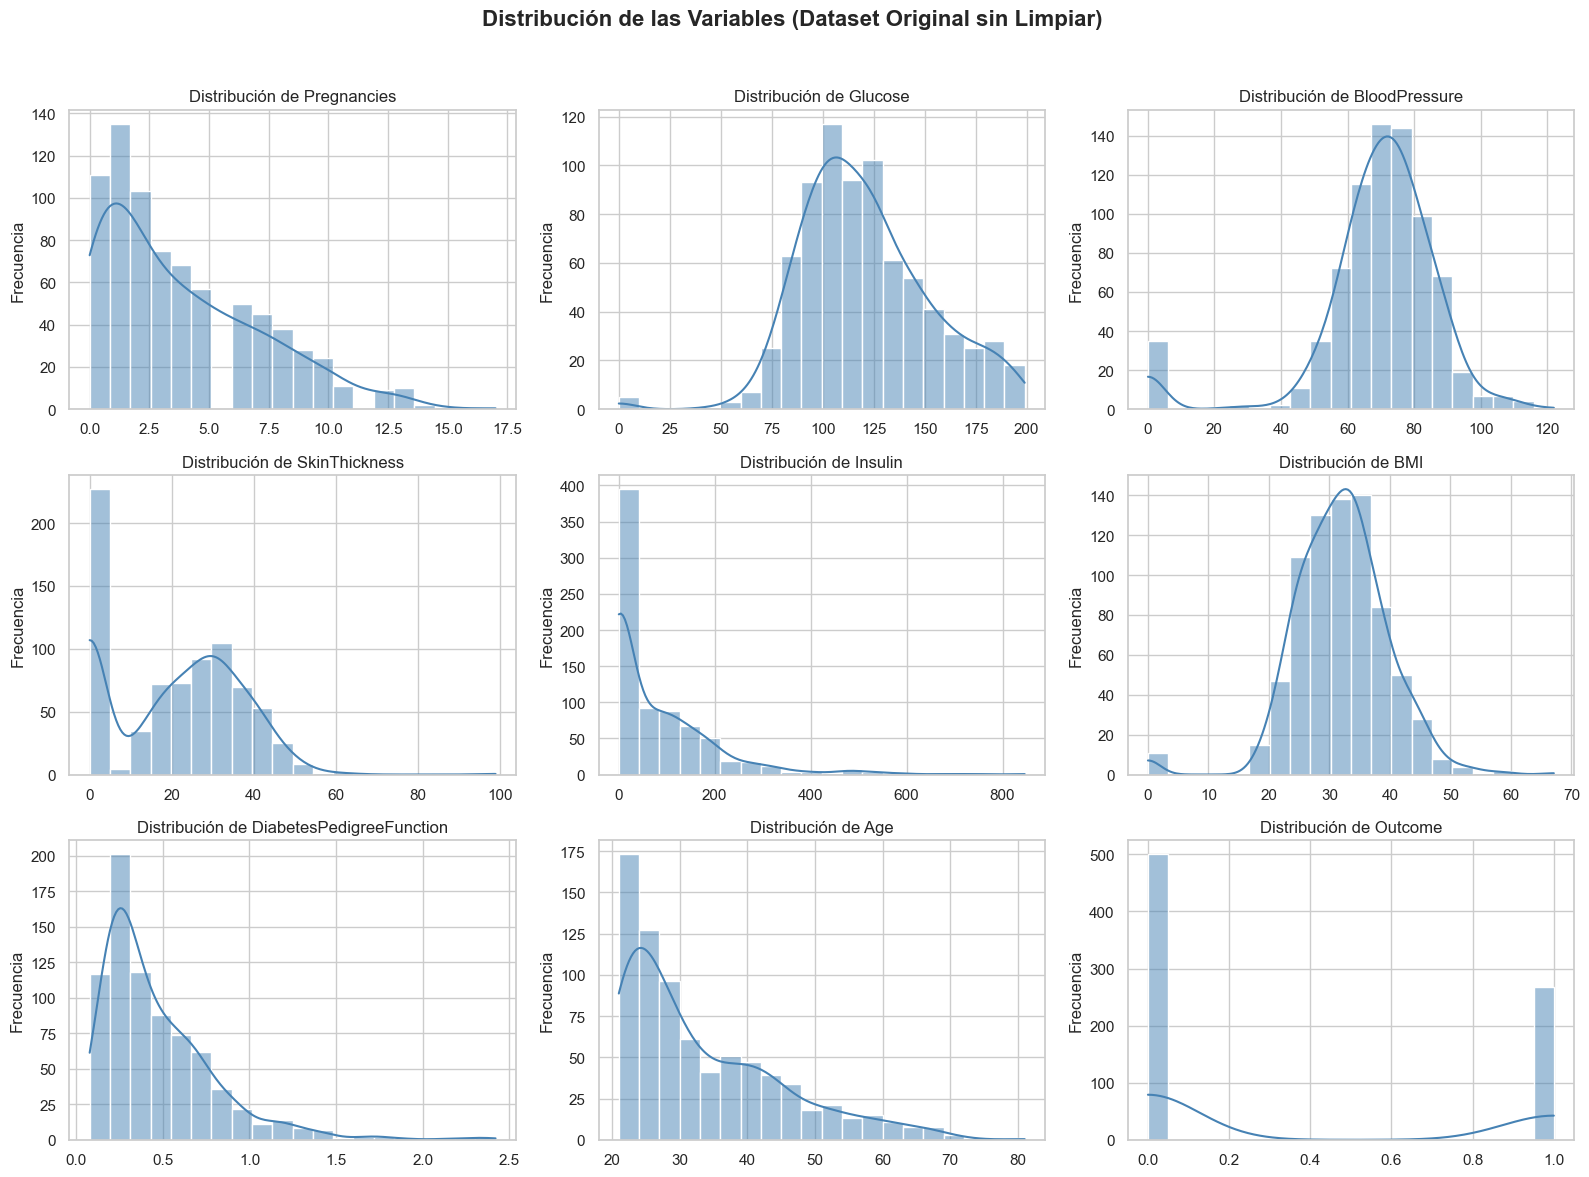

In [12]:
# Cuadrícula de 3x3 histogramas para observar la distribución de todas las variables
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
fig.suptitle('Distribución de las Variables (Dataset Original sin Limpiar)', fontsize=16, fontweight='bold')

columnas = df.columns

for i, col in enumerate(columnas):
    fila = i // 3
    columna = i % 3
    sns.histplot(df[col], kde=True, ax=axes[fila, columna], color='steelblue', bins=20)
    axes[fila, columna].set_title(f'Distribución de {col}', fontsize=12)
    axes[fila, columna].set_xlabel('')
    axes[fila, columna].set_ylabel('Frecuencia')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Interpretación de los Histogramas (Dataset Original)

Al analizar la distribución de cada una de las 9 variables, observamos los siguientes comportamientos:

* **`Pregnancies` (Embarazos):** Presenta un comportamiento lógico con sesgo a la derecha; la mayoría de las pacientes tienen entre 0 y 2 embarazos, y a medida que aumenta el número de hijos la frecuencia disminuye progresivamente. No presenta errores.
* **`Glucose` (Glucosa):** Muestra una distribución en forma de campana (normal) bastante clara, concentrada principalmente entre 75 y 150. Sin embargo, aparece una pequeña barra en `0` que corresponde a datos corruptos, ya que es biológicamente imposible tener glucosa en cero.
* **`BloodPressure` (Presión arterial):** Tiene una forma de campana muy bien definida alrededor de 60 a 80, pero se ve afectada por un grupo de registros en `0` que representan mediciones faltantes (ninguna persona viva tiene presión en cero).
* **`SkinThickness` (Grosor de la piel):** En sus valores válidos sigue una forma de campana cerca de 20 a 40, pero tiene una torre gigante en `0` (más de 200 registros) que distorsiona por completo la gráfica.
* **`Insulin` (Insulina):** Es la variable más afectada por datos corruptos, con casi 400 registros amontonados en `0`. 
* **`BMI` (Índice de Masa Corporal):** Muestra una distribución en campana bien formada (concentrada entre 25 y 40), alterada únicamente por una pequeña cantidad de registros en `0` que son físicamente imposibles.
* **`DiabetesPedigreeFunction` (Antecedentes hereditarios):** Presenta un comportamiento limpio sin ceros inválidos, concentrándose en valores bajos (entre 0.1 y 0.6) y disminuyendo hacia la derecha con algunos valores extremos superiores a 2.0.
* **`Age` (Edad):** Tiene una distribución lógica sin datos corruptos; la mayor parte de la muestra corresponde a mujeres jóvenes (entre 21 y 30 años) y la frecuencia va bajando gradualmente con la edad.
* **`Outcome` (Diagnóstico):** Muestra únicamente dos barras bien diferenciadas en los extremos: alrededor de 500 pacientes sin diabetes (`0`) y cerca de 268 pacientes con diabetes (`1`), lo cual confirma que el dataset está desbalanceado hacia los casos negativos pero sin errores de registro.

### Detección de Valores Atípicos mediante Diagramas de Caja 

Para complementar los histogramas, construimos diagramas de caja para las 8 variables clínicas. Este gráfico permite visualizar cómo se concentran los datos alrededor de la mediana (la línea dentro de cada caja) y detectar fácilmente los valores extremos o atípicos (*outliers*), que aparecen representados como puntos individuales por encima o por debajo de los límites (bigotes) de cada caja.

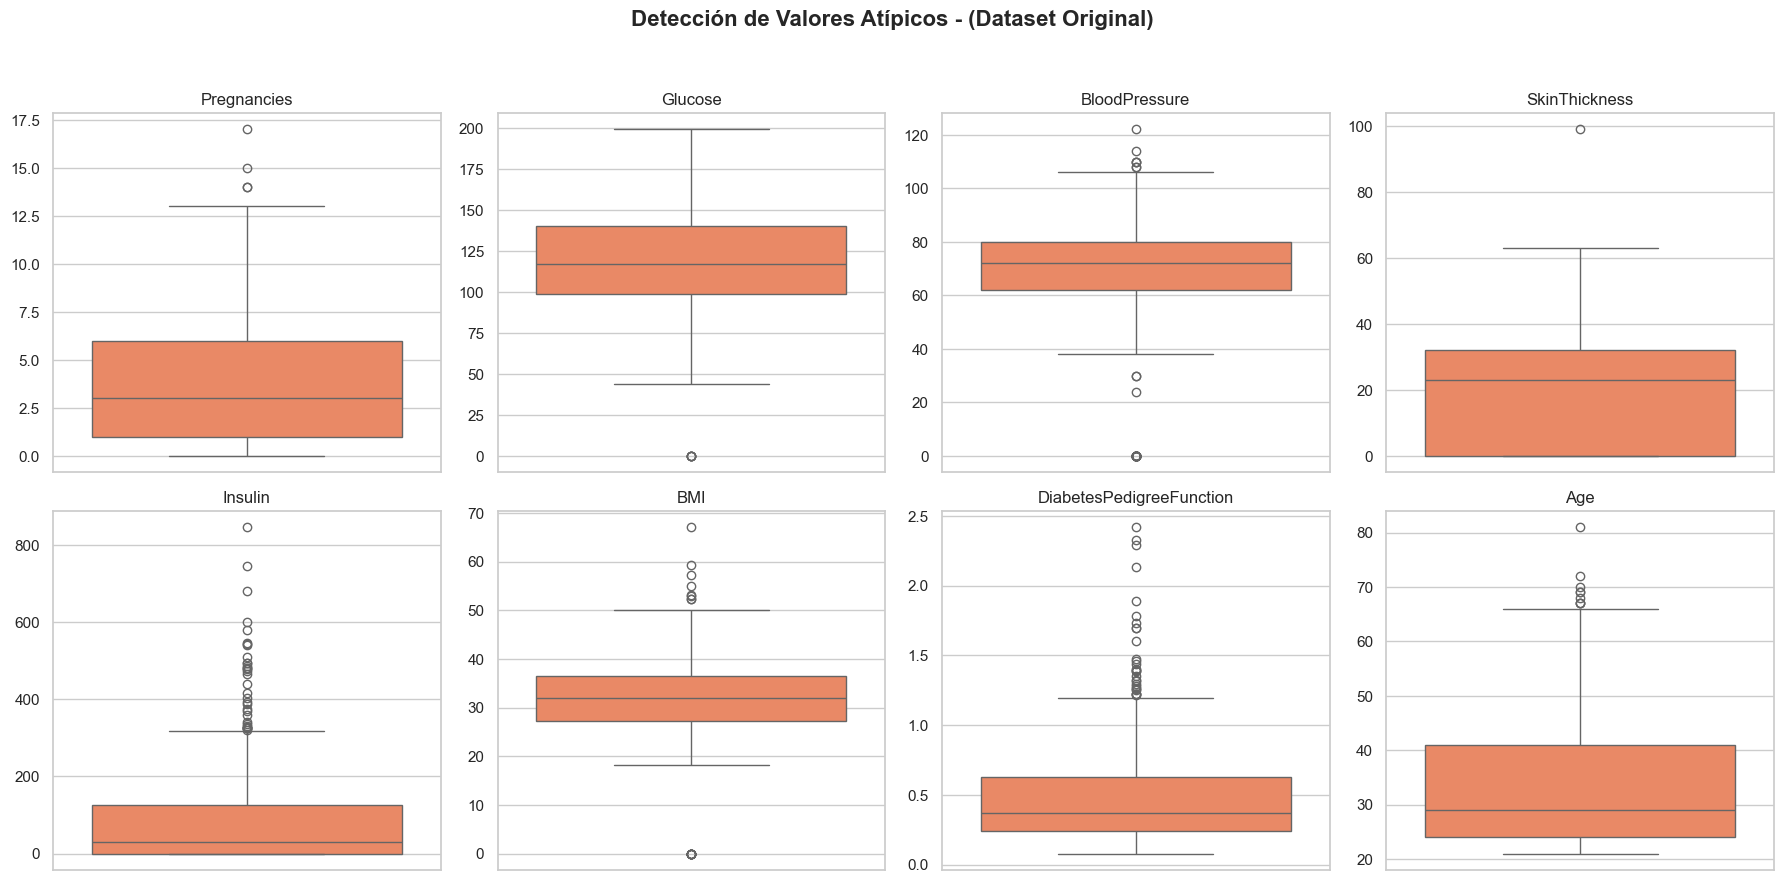

In [13]:
# Diagramas de caja (Boxplots) para identificar valores atípicos en las variables clínicas
variables_clinicas = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('Detección de Valores Atípicos - (Dataset Original)', fontsize=16, fontweight='bold')

for i, col in enumerate(variables_clinicas):
    fila = i // 4
    columna = i % 4
    sns.boxplot(y=df[col], ax=axes[fila, columna], color='coral')
    axes[fila, columna].set_title(col, fontsize=12)
    axes[fila, columna].set_ylabel('')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Interpretación de los Diagramas de Caja 

Al observar los diagramas de caja de las 8 variables clínicas, confirmamos las mismas tendencias vistas en los histogramas y logramos identificar con claridad los valores atípicos (*outliers*):

* **`Pregnancies` y `Age`:** Muestran cajas bien posicionadas sin ceros inválidos. Ambas presentan algunos valores atípicos en la parte superior (pacientes con más de 13 embarazos o mayores de 66 años), lo cual es normal.
* **`Glucose`, `BloodPressure` y `BMI`:** Sus cajas centrales están bien definidas, pero en los tres casos aparecen puntos aislados justo en **`0`** en la parte inferior, confirmando los registros corruptos. Además, `BloodPressure` y `BMI` presentan algunos valores atípicos altos por encima del bigote superior.
* **`SkinThickness` e `Insulin`:** Debido a la enorme cantidad de ceros que contienen, el borde inferior de ambas cajas cae directamente hasta **`0`**. Por otro lado, se hacen visibles valores atípicos extremos hacia arriba (un registro cercano a `100` en `SkinThickness` y una columna de puntos que supera `800` en `Insulin`).
* **`DiabetesPedigreeFunction`:** No presenta datos corruptos en cero, pero muestra una gran cantidad de valores atípicos hacia arriba (superiores a `1.2`), indicando un grupo de pacientes con una carga hereditaria muy alta.

**Conclusión para la limpieza:** La fuerte presencia de valores atípicos altos en variables como `Insulin` y `DiabetesPedigreeFunction` demuestra que **no conviene imputar los datos faltantes con la media (promedio)**, ya que estos extremos la distorsionarían, en su lugar, la **mediana** será una opción mucho más eficiente.

### Distribución de Diagnósticos y Matriz de Correlación (Dataset Original)

Para finalizar la exploración visual inicial, analizamos el balance de la variable objetivo (`Outcome`) y construimos un mapa de calor de correlaciones. Esto nos permite conocer la proporción exacta de pacientes con y sin diabetes, así como identificar qué variables clínicas muestran mayor relación lineal entre sí antes de realizar la imputación de datos.

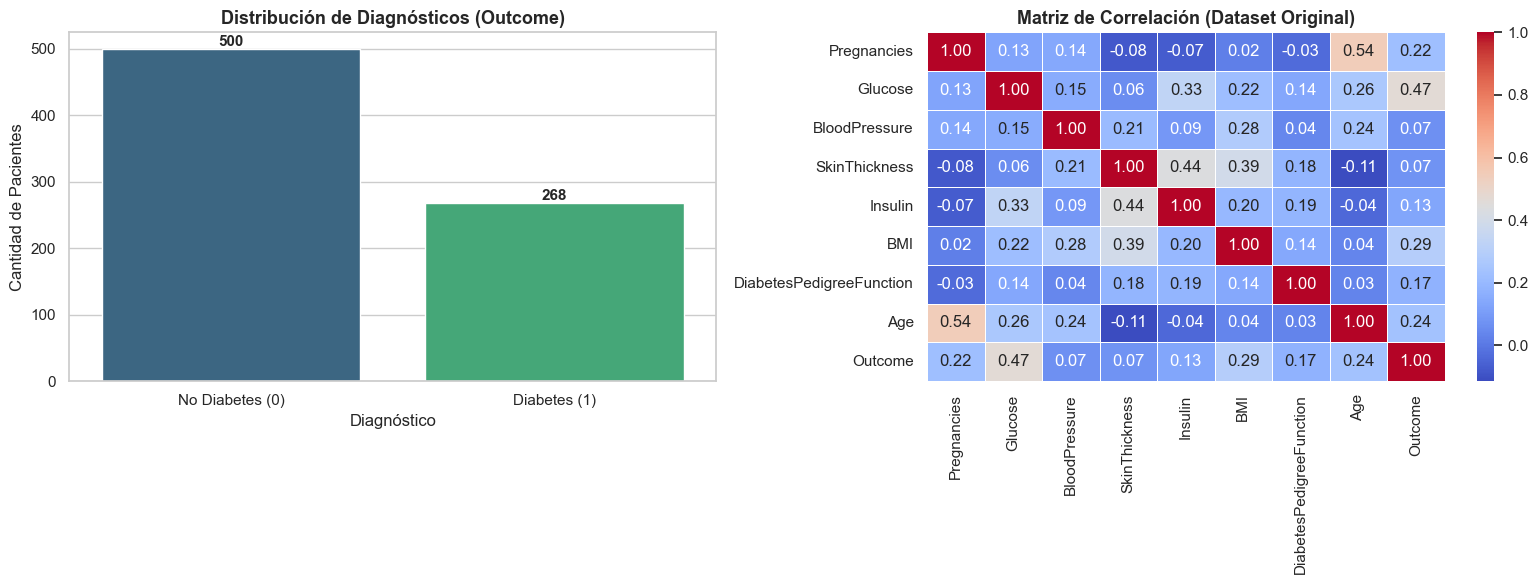

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Conteo de pacientes con y sin diabetes
sns.countplot(x='Outcome', data=df, ax=axes[0], palette='viridis', hue='Outcome', legend=False)
axes[0].set_title('Distribución de Diagnósticos (Outcome)', fontsize=13, fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['No Diabetes (0)', 'Diabetes (1)'])
axes[0].set_xlabel('Diagnóstico')
axes[0].set_ylabel('Cantidad de Pacientes')

# Agregar etiquetas con el número exacto encima de cada barra
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=11, fontweight='bold')

# Gráfico 2: Mapa de calor de correlaciones (Datos crudos)
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1], linewidths=0.5)
axes[1].set_title('Matriz de Correlación (Dataset Original)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

### Conclusiones del Análisis Inicial y Justificación de la Imputación

En esta primera exploración comprobamos que el conjunto de datos tiene bastante sentido clínico: variables como la glucosa, el índice de masa corporal y la edad son las que muestran mayor relación con el diagnóstico de diabetes. Además, mediante los diagramas de caja notamos que varias mediciones presentan valores atípicos extremos hacia arriba.

Sin embargo, los datos del mundo real rara vez vienen perfectos. Al revisar las estadísticas y las gráficas, descubrimos que las mediciones médicas que no se tomaron a ciertas pacientes no se dejaron en blanco, sino que se rellenaron con ceros. Esto ocurre en variables como la glucosa, la presión arterial, el grosor de la piel, la insulina y el índice de masa corporal, donde un cero es biológicamente imposible.

Si dejáramos estos datos corruptos sin corregir, distorsionarían los promedios y engañarían a cualquier algoritmo de *Machine Learning* haciéndole creer que esos valores imposibles son reales. Por otro lado, tampoco es viable eliminar las filas incompletas, ya que columnas como la insulina y el grosor de la piel tienen demasiados registros afectados y perderíamos gran parte de la muestra. Por ello, la mejor solución es aplicar **imputación utilizando la mediana**, lo que nos permite recuperar esos datos faltantes sin que los valores atípicos extremos alteren el resultado.

## Limpieza e Imputación de Datos Corruptos

Para corregir los datos inconsistentes sin alterar los ceros que sí son válidos (`Pregnancies` y `Outcome`), creamos una copia del conjunto de datos original y reemplazamos por `NaN` (valor nulo real) los registros iguales a `0` en las cinco variables clínicas afectadas (`Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` y `BMI`). 

Luego, volvemos a ejecutar la inspección de valores faltantes del libro guía para comprobar que Pandas ahora sí detecta correctamente todos los registros incompletos.

Creamos una copia del dataset original para conservar el original para poder compararlo luego

In [17]:
df_limpio = df.copy()
display(df_limpio.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Definimos las 5 columnas donde el valor 0 es biológicamente imposible

In [18]:
columnas_corruptas = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

Reemplazamos los 0 por NaN únicamente en esas columnas

In [19]:
df_limpio[columnas_corruptas] = df_limpio[columnas_corruptas].replace(0, np.nan)

Volvemos a ejecutar la detección de valores faltantes del libro guía

In [21]:
print("Columns with Missing Values::", df_limpio.columns[df_limpio.isnull().any()].tolist())
print("Number of rows with Missing Values::", len(df_limpio.isnull().any(axis=1).to_numpy().nonzero()[0].tolist()))
print("Sample Indices with missing data::", df_limpio.isnull().any(axis=1).to_numpy().nonzero()[0].tolist()[0:5])

Columns with Missing Values:: ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
Number of rows with Missing Values:: 376
Sample Indices with missing data:: [0, 1, 2, 5, 7]


Al convertir los ceros imposibles en valores nulos (`NaN`), confirmamos que **376 de las 768 filas** presentan algún dato faltante, lo que confirma que eliminar registros no es una opción viable porque perderíamos casi la mitad de la muestra.

Para recuperar estos datos sin distorsionar el comportamiento real del conjunto de datos, aplicamos **imputación por la mediana** en cada una de las cinco columnas afectadas. Elegimos la mediana en lugar de la media (promedio) porque, como vimos en los diagramas de caja, varias variables tienen valores atípicos muy altos que arrastrarían el promedio hacia arriba, mientras que la mediana mantiene un valor central estable y representativo.

### Aplicación de Imputación con la Mediana

Calculamos la mediana de cada una de las 5 columnas afectadas (ignorando los NaN)

In [22]:
medianas = df_limpio[columnas_corruptas].median()

In [23]:
medianas

Glucose          117.0
BloodPressure     72.0
SkinThickness     29.0
Insulin          125.0
BMI               32.3
dtype: float64

Rellenamos los valores NaN con la mediana correspondiente de cada columna

In [24]:
df_limpio[columnas_corruptas] = df_limpio[columnas_corruptas].fillna(medianas)

Comprobamos que ya no queden valores nulos en todo el DataFrame

In [26]:
print(df_limpio.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


## Verificación Post-Imputación (*Understanding Data*)

Una vez imputados los datos faltantes con la mediana, volvemos a ejecutar los pasos de inspección de la sección *"Understanding Data"* sobre el conjunto de datos limpio. El objetivo es confirmar que ya no existen valores nulos, que se conservaron los 768 registros originales y que las estadísticas descriptivas (especialmente los valores mínimos) ahora reflejan mediciones coherentes.

Geometría y muestra de las primeras filas ya corregidas

In [30]:
print(f"Dimensiones del dataset limpio: {df_limpio.shape}")
display(df_limpio.head())

Dimensiones del dataset limpio: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


Verificación de los valores faltantes

In [29]:
print("\nColumns with Missing Values::", df_limpio.columns[df_limpio.isnull().any()].tolist())
print("Number of rows with Missing Values::", len(df_limpio.isnull().any(axis=1).to_numpy().nonzero()[0].tolist()))
print("Sample Indices with missing data::", df_limpio.isnull().any(axis=1).to_numpy().nonzero()[0].tolist()[0:5])


Columns with Missing Values:: []
Number of rows with Missing Values:: 0
Sample Indices with missing data:: []


Estadisticas generales y resumen estadistico actualizado

In [31]:
print("\nGeneral Stats::")
df_limpio.info()


General Stats::
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    float64
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    float64
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB


In [32]:
print("\nSummary Stats (Dataset Limpio)::")
display(df_limpio.describe())


Summary Stats (Dataset Limpio)::


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.656250,72.386719,29.108073,140.671875,32.455208,0.471876,33.240885,0.348958
std,3.369578,30.438286,12.096642,8.791221,86.383060,6.875177,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### Interpretación de la Verificación Post-Imputación

Al volver a ejecutar los pasos de *"Understanding Data"* sobre el conjunto de datos ya corregido, comprobamos que la limpieza fue exitosa:

* **Integridad de la muestra:** Se conservaron intactos los **768 registros y 9 columnas** originales, logrando eliminar el 100% de los valores nulos.
* **Estadísticas coherentes:** En el nuevo resumen estadístico (`describe()`), los valores mínimos (`min`) de las cinco variables clínicas ya no aparecen en cero, sino que muestran mediciones reales y biológicamente posibles.
* **Ceros únicamente donde tienen sentido:** El conteo final confirma que ya no hay ceros corruptos en las mediciones médicas, los únicos ceros que permanecen en la tabla corresponden a `Pregnancies` (cero embarazos) y `Outcome` (diagnóstico negativo), donde son completamente válidos.

## Visualización Comparativa (Antes vs. Después de la Imputación)

Para comprobar de forma visual el efecto de la limpieza, comparamos lado a lado las gráficas obtenidas con el **dataset original (izquierda)** frente al **dataset limpio tras imputar con la mediana (derecha)**.

### Comparativa de Histogramas 

Observamos cómo evolucionó la distribución de las 9 variables después de reemplazar los ceros biológicamente imposibles por la mediana de cada columna.

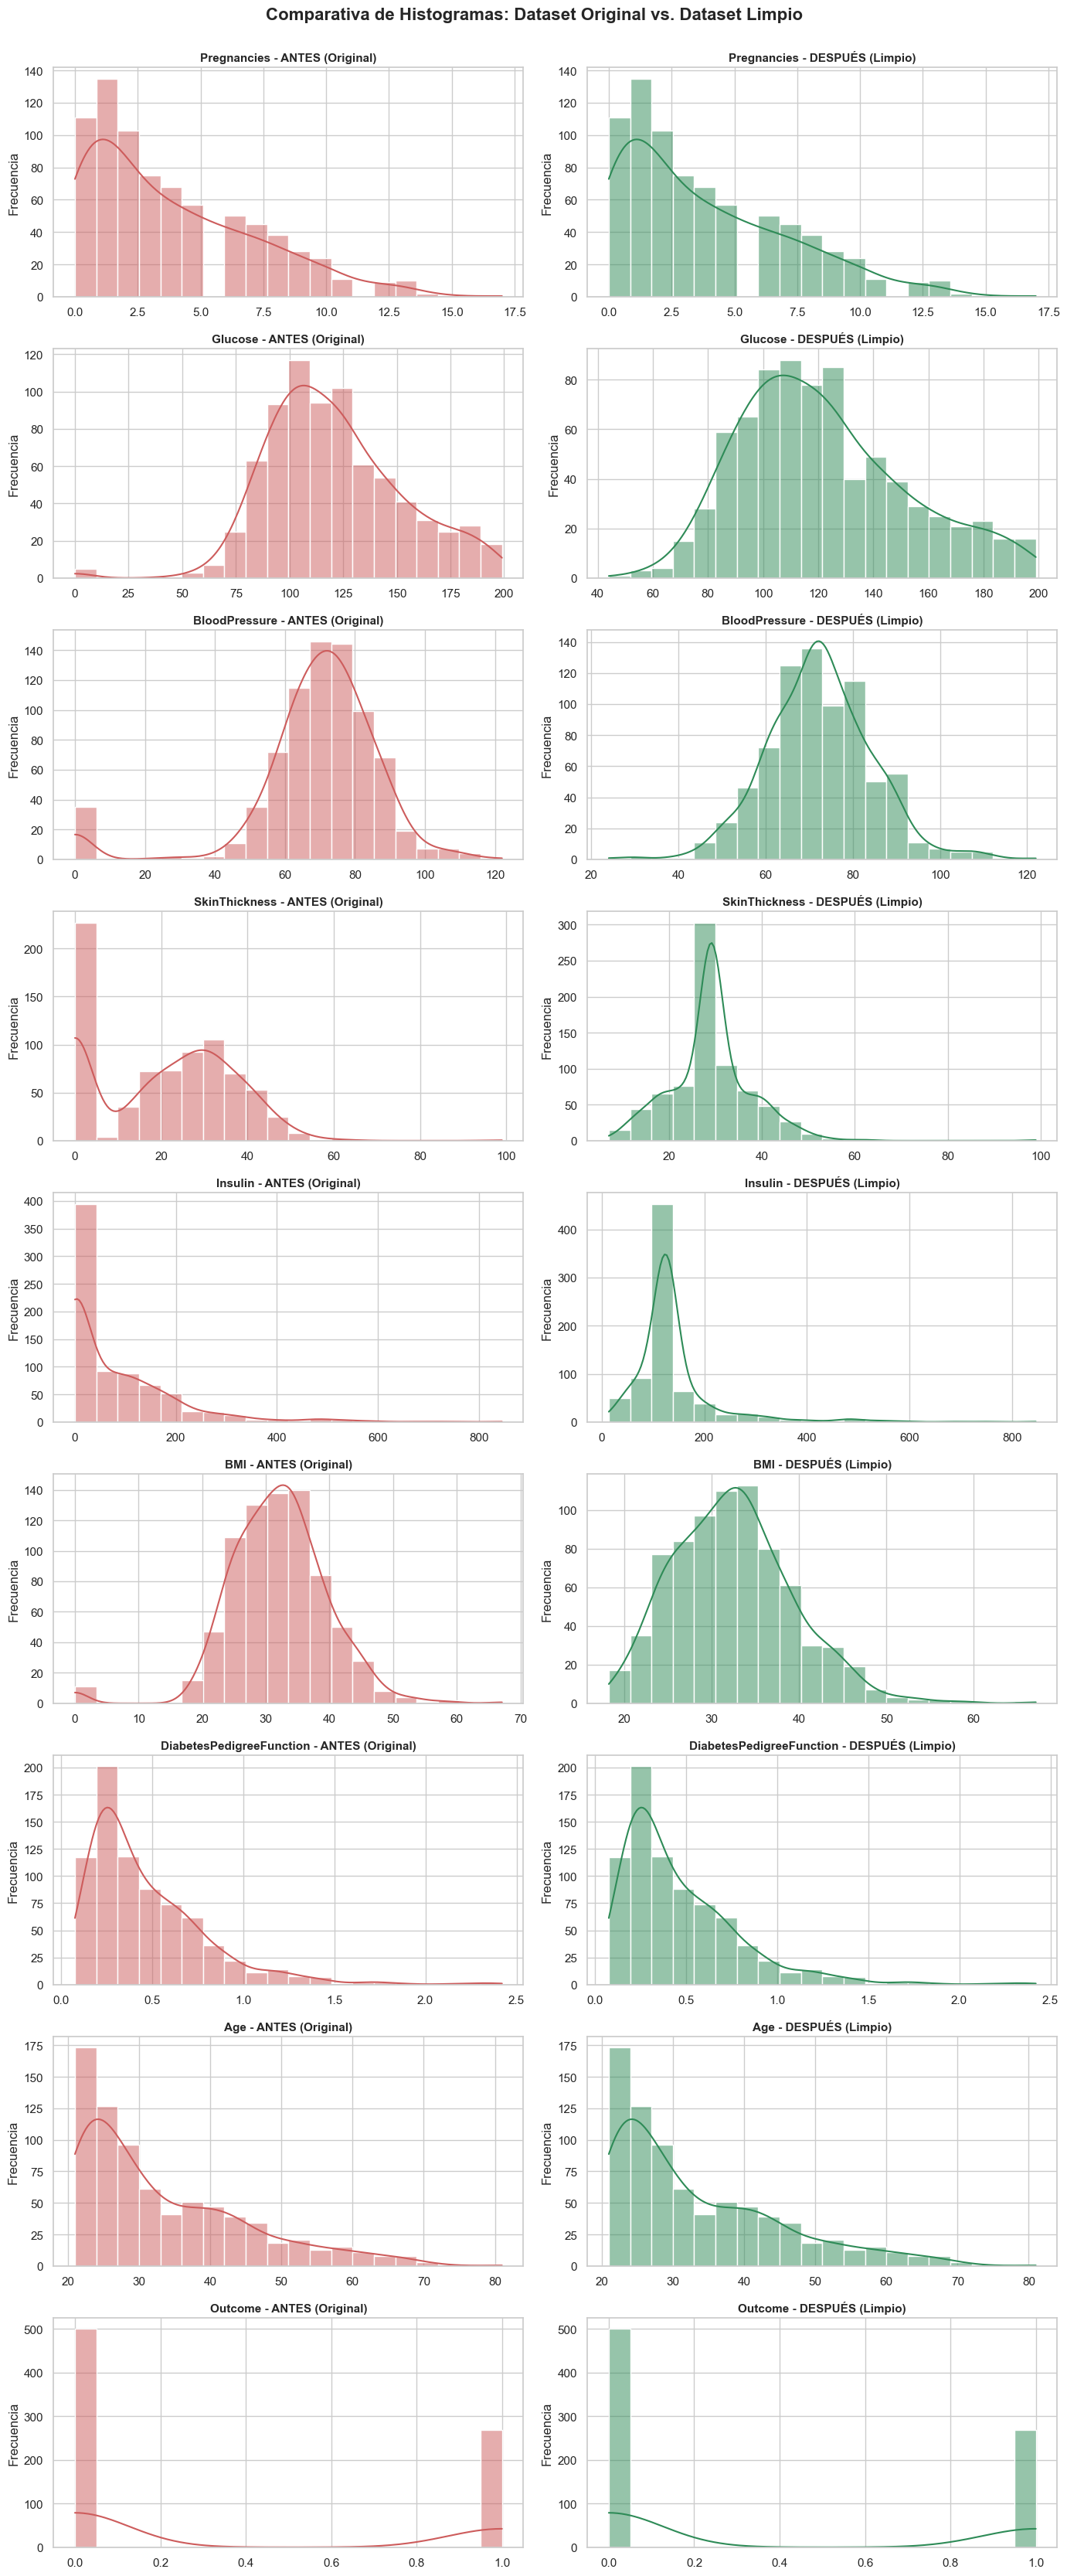

In [33]:
columnas = df.columns

fig, axes = plt.subplots(9, 2, figsize=(14, 34))
fig.suptitle('Comparativa de Histogramas: Dataset Original vs. Dataset Limpio', fontsize=16, fontweight='bold')

for i, col in enumerate(columnas):
    # Columna izquierda: Dataset Original (Antes)
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='indianred', bins=20)
    axes[i, 0].set_title(f'{col} - ANTES (Original)', fontsize=11, fontweight='bold')
    axes[i, 0].set_xlabel('')
    axes[i, 0].set_ylabel('Frecuencia')
    
    # Columna derecha: Dataset Limpio (Después)
    sns.histplot(df_limpio[col], kde=True, ax=axes[i, 1], color='seagreen', bins=20)
    axes[i, 1].set_title(f'{col} - DESPUÉS (Limpio)', fontsize=11, fontweight='bold')
    axes[i, 1].set_xlabel('')
    axes[i, 1].set_ylabel('Frecuencia')

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

Al comparar lado a lado las distribuciones originales (izquierda) contra las distribuciones limpias (derecha), observamos tres resultados clave:

* **Variables sin errores intactas:** Columnas como `Pregnancies`, `DiabetesPedigreeFunction`, `Age` y `Outcome` mantienen exactamente la misma forma antes y después, comprobando que la limpieza respetó los registros válidos.
* **Recuperación de distribuciones naturales (`Glucose`, `BloodPressure` y `BMI`):** En estas variables, que tenían pocos ceros corruptos, desaparecieron las barras aisladas en `0` y los ejes ahora comienzan en valores médicos reales, dejando curvas en forma de campana muy limpias.
* **Concentración en la mediana (`SkinThickness` e `Insulin`):** Como estas dos columnas tenían un porcentaje muy alto de mediciones faltantes, al reemplazar los ceros por la mediana desaparece el pico falso en `0` y se forma una barra central más alta alrededor de sus medianas (`29.0` y `125.0`), conservando toda la muestra sin distorsionar los extremos.

### Comparativa de Diagramas de Caja : Antes vs. Después

Comparamos lado a lado los diagramas de caja de las 8 variables clínicas para observar cómo se corrigieron los valores imposibles en la parte inferior y cómo se reajustaron las cajas alrededor de la mediana tras la imputación.

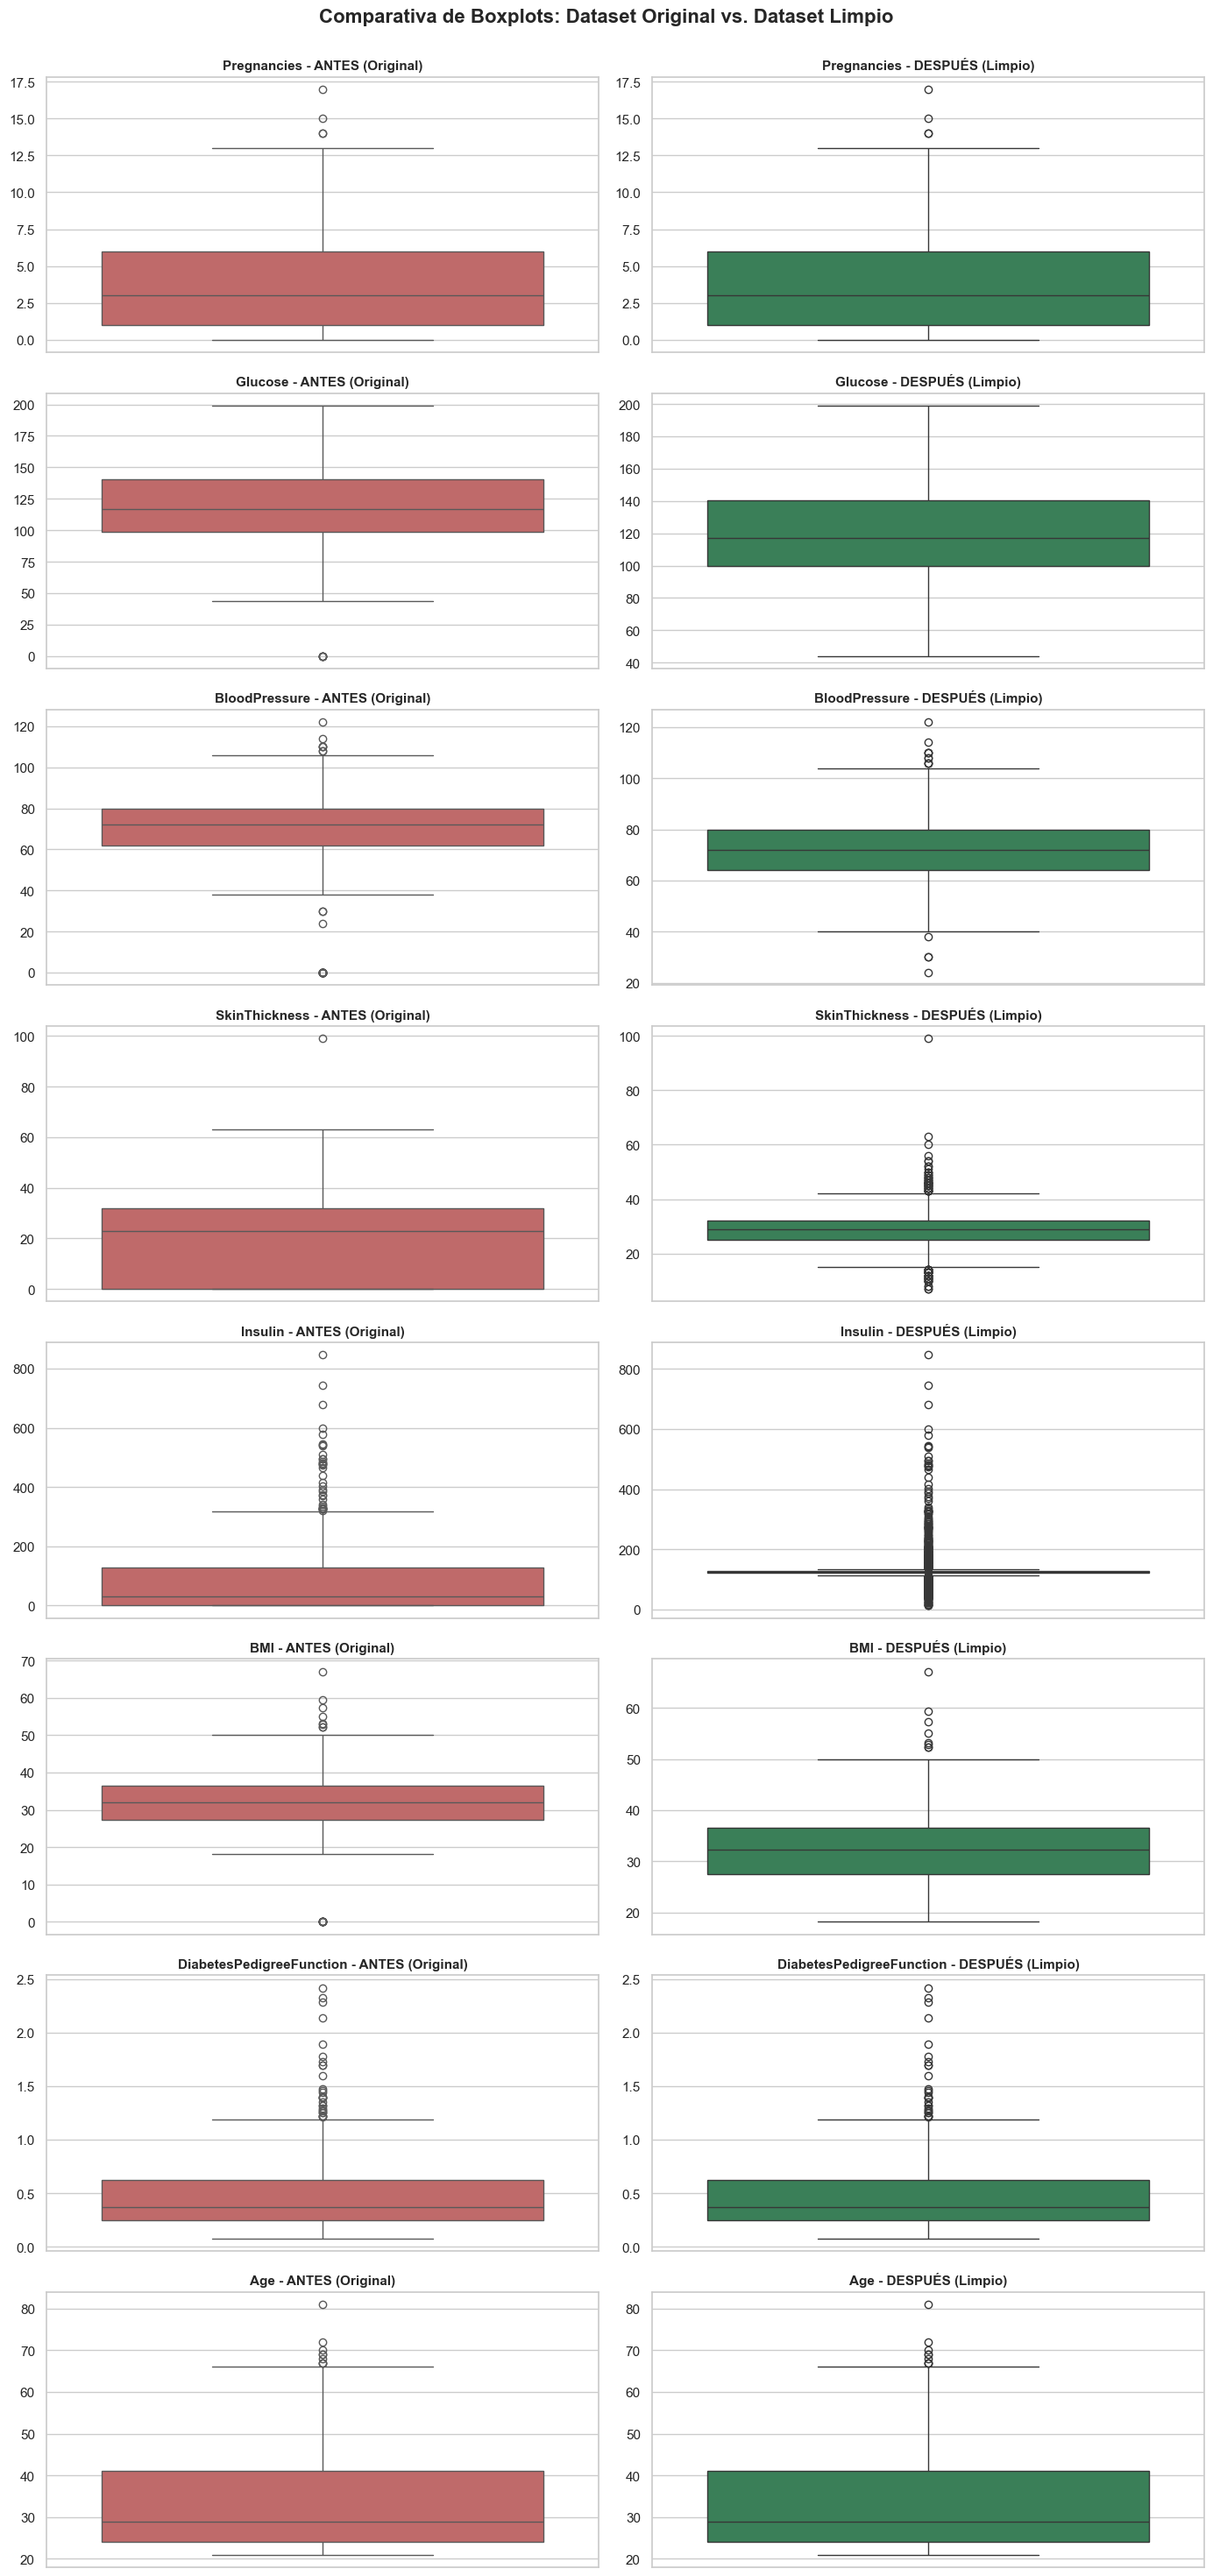

In [34]:
variables_clinicas = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

fig, axes = plt.subplots(8, 2, figsize=(14, 30))
fig.suptitle('Comparativa de Boxplots: Dataset Original vs. Dataset Limpio', fontsize=16, fontweight='bold')

for i, col in enumerate(variables_clinicas):
    # Columna izquierda: Dataset Original (Antes)
    sns.boxplot(y=df[col], ax=axes[i, 0], color='indianred')
    axes[i, 0].set_title(f'{col} - ANTES (Original)', fontsize=11, fontweight='bold')
    axes[i, 0].set_ylabel('')
    
    # Columna derecha: Dataset Limpio (Después)
    sns.boxplot(y=df_limpio[col], ax=axes[i, 1], color='seagreen')
    axes[i, 1].set_title(f'{col} - DESPUÉS (Limpio)', fontsize=11, fontweight='bold')
    axes[i, 1].set_ylabel('')

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

### Interpretación de la Comparativa de Diagramas de Caja (*Boxplots*)

Al comparar los diagramas de caja originales (izquierda) frente a los limpios (derecha), observamos el impacto directo de la imputación:

* **Eliminación de valores imposibles (`Glucose`, `BloodPressure` y `BMI`):** En estas tres variables desaparecieron por completo los puntos aislados en `0` de la parte inferior, manteniendo intactos los valores atípicos altos que sí corresponden a mediciones clínicas reales.
* **Reajuste de `SkinThickness` e `Insulin`:** Ambas cajas dejaron de estar arrastradas hacia el `0`. En `SkinThickness`, la caja se ubicó de forma compacta alrededor de su mediana. En `Insulin`, debido a que casi la mitad de los registros fueron imputados con la misma mediana, la caja central se estrechó prácticamente en una línea sobre ese valor, dejando visibles todos los registros reales dispersos por encima y por debajo.
* **Variables sin errores intactas:** `Pregnancies`, `DiabetesPedigreeFunction` y `Age` conservaron exactamente la misma estructura y valores atípicos originales.

### Comparativa de Matrices de Correlación: Antes vs. Después

Comparamos lado a lado las matrices de correlación del **dataset original (izquierda)** frente al **dataset limpio (derecha)** para identificar cómo cambiaron las relaciones entre las variables al eliminar los ceros inválidos.

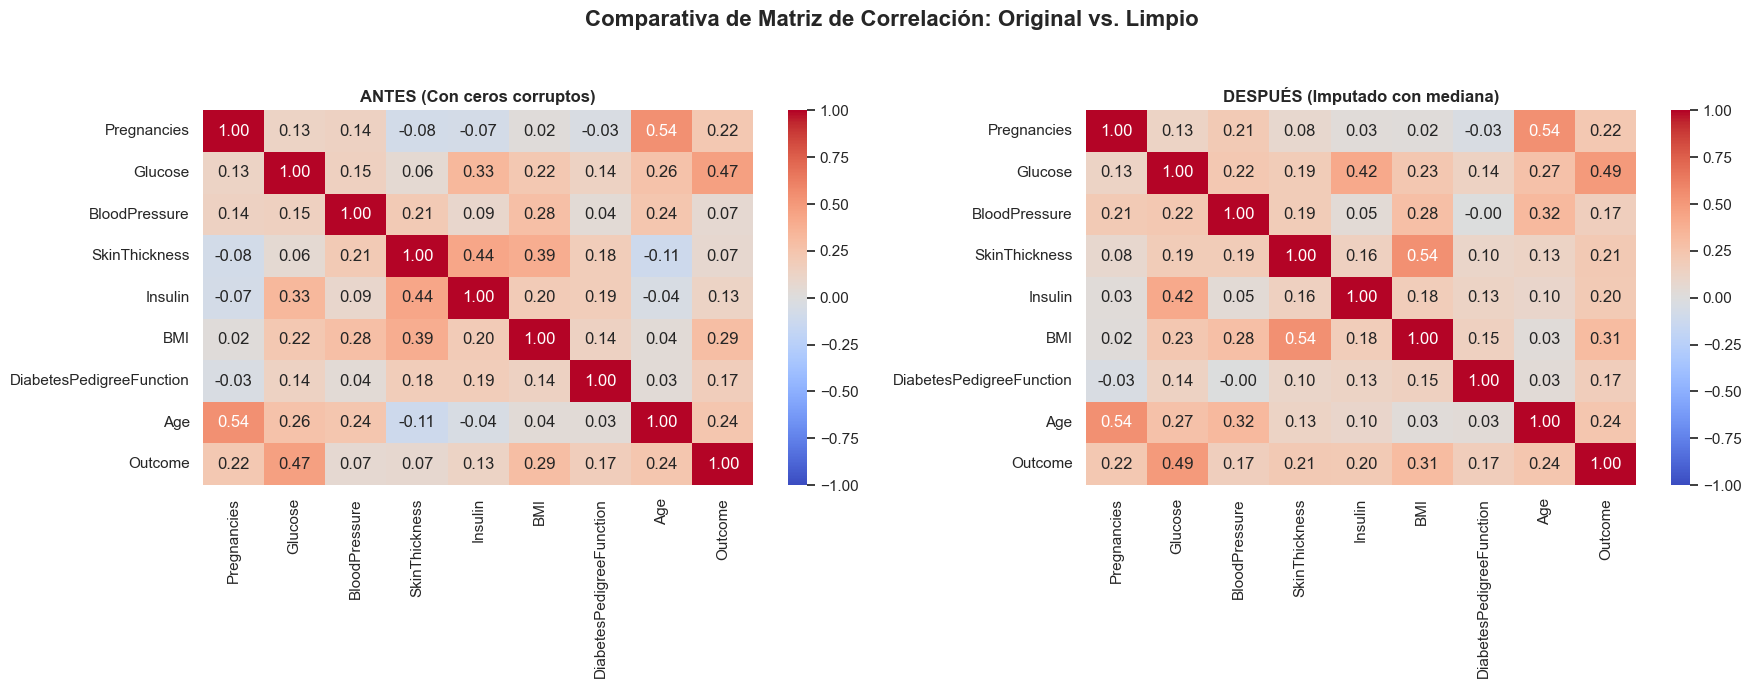

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Comparativa de Matriz de Correlación: Original vs. Limpio', fontsize=16, fontweight='bold')

# Izquierda: Matriz Original (Antes)
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('ANTES (Con ceros corruptos)', fontsize=12, fontweight='bold')

# Derecha: Matriz Limpia (Después)
sns.heatmap(df_limpio.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('DESPUÉS (Imputado con mediana)', fontsize=12, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Al comparar ambos mapas de calor, se nota claramente cómo la limpieza eliminó el ruido que provocaban los ceros inválidos, desaparecieron las correlaciones negativas irreales, se fortalecieron los vínculos biológicos naturales entre las mediciones médicas y quedó mucho más clara la relación positiva de todas las variables con la diabetes, destacando la glucosa y el índice de masa corporal

## Conclusión

Este ejercicio demuestra que analizar, limpiar y organizar los datos antes de llevarlos a un algoritmo de *Machine Learning* es un paso indispensable. A simple vista, el conjunto de datos parecía completo al no presentar valores nulos tradicionales, sin embargo, el análisis exploratorio y las visualizaciones permitieron descubrir errores ocultos, como los ceros biológicamente imposibles en varias mediciones clínicas.

Al aplicar una limpieza adecuada reemplazando esos valores corruptos por la mediana para no afectar los datos por culpa de valores extremos, se recuperó la coherencia real de las variables y sus relaciones. Preparar bien la información desde el inicio evita que los modelos aprendan patrones falsos o ruido, garantizando predicciones mucho más precisas y confiables.